# Analyse : croissance économique, émissions de CO₂ et éducation

Ce notebook fait suite au notebook de préparation. Celui-ci a nettoyé les six fichiers sources et construit un modèle en étoile, enregistré dans le dossier `data/mart`. Ici, on se contente de lire ce modèle et d'analyser les données pour répondre aux trois questions posées par la direction logistique, qui cherche une nouvelle zone d'implantation.

1. Quels pays ont connu la plus forte croissance du PIB entre deux années données ?
2. Quelle est la corrélation entre les émissions de CO₂ et le niveau d'éducation dans différents pays ?
3. Quels pays ont la plus faible empreinte carbone par habitant, et comment cela évolue-t-il au fil des années ?

Les résultats sont ensuite présentés dans le tableau de bord Power BI. Ce notebook sert à justifier les choix de méthode et les chiffres affichés.

#### Les données utilisées

Le modèle contient trois tables. La table de faits `fait_indicateurs_pays_annee` contient une ligne par pays et par année, de 2000 à 2021, avec les indicateurs : PIB, population, émissions de CO₂ par habitant, dépenses d'éducation et autres. La dimension `dim_pays` décrit chaque pays (nom, continent, taille de la population), et la dimension `dim_annee` décrit les années.

#### Hypothèses communes à toute l'analyse

On ne garde que les pays de plus d'un million d'habitants. Les très petits pays ont des valeurs par habitant instables, qui peuvent changer fortement d'une année à l'autre pour une seule usine ou un seul grand projet, et ils ne sont pas des marchés d'implantation pertinents pour une entreprise internationale.

Le PIB est exprimé en dollars américains courants. Ses variations incluent donc l'inflation et les effets de change, et pas seulement la hausse de la production.

Les émissions de CO₂ sont des émissions territoriales par habitant : elles comptent ce qui est émis sur le territoire du pays, et non ce qui est contenu dans les produits qu'il importe.

L'éducation est mesurée par les dépenses publiques consacrées à l'enseignement primaire, en pourcentage du PIB. C'est le seul indicateur d'éducation disponible.

La ligne Monde (code WLD) sert de référence pour situer chaque pays.

Les noms de pays sont conservés en anglais, tels qu'ils figurent dans les sources, pour rester identiques à ceux du tableau de bord. Les commentaires citent les chiffres obtenus sur les données du mart au moment de l'analyse : si les données sont mises à jour, les tableaux changent mais les textes doivent être relus.

Les résultats calculés ici pour le tableau de bord sont enregistrés dans un dossier séparé, `data/resultats`. Le dossier `data/mart` ne contient que le modèle produit par le notebook de préparation.

#### Plan

0. Configuration et fonctions
1. Question a : croissance du PIB
2. Les émissions de CO₂ dans le temps, socle commun aux questions b et c
3. Question b : émissions de CO₂ et éducation
4. Question c : pays à la plus faible empreinte carbone
5. Synthèse : croiser croissance et empreinte carbone

## 0. Configuration et fonctions

Toutes les fonctions sont regroupées ici, par question, pour que les parties d'analyse restent courtes et lisibles. Chaque fonction lit le modèle avec DuckDB, qui permet d'interroger directement les fichiers CSV du mart en SQL.

### 0.1 Bibliothèques et chargement du modèle

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from scipy import stats

DOSSIER_MART = Path("data/mart")
DOSSIER_RESULTATS = Path("data/resultats")
DOSSIER_RESULTATS.mkdir(parents=True, exist_ok=True)

# Les trois tables du modèle, déclarées comme vues pour être interrogées en SQL
for table in ["fait_indicateurs_pays_annee", "dim_pays", "dim_annee"]:
    duckdb.sql(f"CREATE OR REPLACE VIEW {table} AS SELECT * FROM read_csv_auto('{DOSSIER_MART / table}.csv')")

# Mêmes couleurs de continents que dans le tableau de bord Power BI
COULEURS_CONTINENTS = {
    "Afrique": "#12239E", "Amérique": "#6B007B", "Asie": "#118DFF",
    "Europe": "#E66C37", "Océanie": "#E044A7",
}

# Filtre commun : pays de plus d'un million d'habitants, hors ligne Monde
FILTRE_PAYS = "p.type_entite = 'Pays' AND p.plus_d_un_million"

### 0.2 Fonctions de la question a

In [2]:
def croissance_pib(annee_debut, annee_fin):
    """Croissance totale, annuelle et par habitant du PIB de chaque pays entre deux années."""
    nb_annees = annee_fin - annee_debut
    return duckdb.sql(f"""
        WITH debut AS (
            SELECT code_iso, pib_usd, pib_usd * 1000 / population_milliers AS pib_hab
            FROM fait_indicateurs_pays_annee
            WHERE annee = {annee_debut} AND pib_usd IS NOT NULL
        ),
        fin AS (
            SELECT code_iso, pib_usd, pib_usd * 1000 / population_milliers AS pib_hab
            FROM fait_indicateurs_pays_annee
            WHERE annee = {annee_fin} AND pib_usd IS NOT NULL
        )
        SELECT p.nom_pays, p.continent,
               d.pib_usd / 1e9                                          AS pib_debut_mds,
               f.pib_usd / 1e9                                          AS pib_fin_mds,
               (f.pib_usd / d.pib_usd - 1) * 100                        AS croissance_pct,
               (POWER(f.pib_usd / d.pib_usd, 1 / {nb_annees}) - 1) * 100 AS croissance_annuelle_pct,
               (f.pib_hab / d.pib_hab - 1) * 100                        AS croissance_pib_hab_pct
        FROM debut d
        JOIN fin f USING (code_iso)
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS}
        ORDER BY croissance_pct DESC
    """).df()


def repartition_croissance(classement):
    """Centiles de la croissance annuelle et nombre de pays en recul ou en très forte croissance."""
    taux = classement["croissance_annuelle_pct"]
    centiles = taux.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).rename(lambda q: f"centile {int(q * 100)}")
    reperes = pd.Series({
        "pays en recul (moins de 0 %)": (taux < 0).sum(),
        "pays à plus de 8 % par an": (taux > 8).sum(),
    })
    return centiles, reperes

### 0.3 Fonctions sur les émissions de CO₂ (partie 2)

In [3]:
def evolution_monde():
    """Émissions mondiales par habitant et leur variation d'une année sur l'autre."""
    monde = duckdb.sql("""
        SELECT annee, emissions_t_hab
        FROM fait_indicateurs_pays_annee
        WHERE code_iso = 'WLD'
        ORDER BY annee
    """).df().set_index("annee")
    monde["variation_pct"] = monde["emissions_t_hab"].pct_change() * 100
    return monde


def emissions_par_continent():
    """Émissions par habitant de chaque continent, pondérées par la population moyenne de chaque pays."""
    return duckdb.sql(f"""
        WITH poids AS (
            SELECT code_iso, AVG(population_milliers) AS population
            FROM fait_indicateurs_pays_annee
            GROUP BY code_iso
        )
        SELECT f.annee, p.continent,
               SUM(f.emissions_t_hab * w.population) / SUM(w.population) AS emissions
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        JOIN poids w USING (code_iso)
        WHERE {FILTRE_PAYS} AND f.emissions_t_hab IS NOT NULL
        GROUP BY ALL
    """).df().pivot(index="annee", columns="continent", values="emissions")


def dispersion_emissions():
    """Centiles des émissions par habitant entre pays, pour chaque année."""
    dispersion = duckdb.sql(f"""
        SELECT f.annee,
               COUNT(*)                               AS nb_pays,
               QUANTILE_CONT(f.emissions_t_hab, 0.10) AS p10,
               QUANTILE_CONT(f.emissions_t_hab, 0.25) AS q1,
               MEDIAN(f.emissions_t_hab)              AS mediane,
               QUANTILE_CONT(f.emissions_t_hab, 0.75) AS q3,
               QUANTILE_CONT(f.emissions_t_hab, 0.90) AS p90
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS} AND f.emissions_t_hab IS NOT NULL
        GROUP BY f.annee
        ORDER BY f.annee
    """).df().set_index("annee")
    dispersion["rapport_p90_p10"] = dispersion["p90"] / dispersion["p10"]
    return dispersion


def variation_emissions(annee_debut, annee_fin):
    """Émissions par habitant de chaque pays aux deux années, et leur variation en tonnes et en %."""
    return duckdb.sql(f"""
        WITH emissions AS (
            SELECT f.code_iso, p.nom_pays, p.continent, f.annee, f.emissions_t_hab
            FROM fait_indicateurs_pays_annee f
            JOIN dim_pays p USING (code_iso)
            WHERE {FILTRE_PAYS} AND f.emissions_t_hab IS NOT NULL
        )
        SELECT debut.code_iso, debut.nom_pays, debut.continent,
               debut.emissions_t_hab                                   AS emissions_debut,
               fin.emissions_t_hab                                     AS emissions_fin,
               fin.emissions_t_hab - debut.emissions_t_hab             AS variation_t,
               (fin.emissions_t_hab / debut.emissions_t_hab - 1) * 100 AS variation_pct
        FROM emissions debut
        JOIN emissions fin
          ON debut.code_iso = fin.code_iso
         AND debut.annee = {annee_debut}
         AND fin.annee = {annee_fin}
        ORDER BY variation_t
    """).df()


def trajectoires_emissions(codes_pays, titre):
    """Trace tous les pays en gris et met en couleur les pays demandés."""
    series = duckdb.sql(f"""
        SELECT f.code_iso, p.nom_pays, f.annee, f.emissions_t_hab
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS} AND f.emissions_t_hab IS NOT NULL
    """).df()

    fig, ax = plt.subplots(figsize=(11, 6))
    for _, pays in series.groupby("code_iso"):
        ax.plot(pays["annee"], pays["emissions_t_hab"], color="lightgrey", linewidth=0.6)
    for code in codes_pays:
        pays = series[series["code_iso"] == code]
        ax.plot(pays["annee"], pays["emissions_t_hab"], linewidth=2.5, label=pays["nom_pays"].iloc[0])
    ax.set_yscale("log")
    ax.set_title(titre)
    ax.set_xlabel("Année")
    ax.set_ylabel("t CO₂ par habitant (échelle log)")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.3, which="both")
    plt.show()

### 0.4 Fonctions de la question b

In [4]:
def couverture_education():
    """Nombre de pays renseignés et quartiles des dépenses d'éducation, pour chaque année."""
    return duckdb.sql(f"""
        SELECT f.annee,
               COUNT(*) FILTER (WHERE f.depenses_education_pct_pib IS NOT NULL
                                  AND f.emissions_t_hab IS NOT NULL) AS nb_pays_deux_variables,
               QUANTILE_CONT(f.depenses_education_pct_pib, 0.25)     AS q1,
               MEDIAN(f.depenses_education_pct_pib)                  AS mediane,
               QUANTILE_CONT(f.depenses_education_pct_pib, 0.75)     AS q3
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS}
        GROUP BY f.annee
        HAVING COUNT(f.depenses_education_pct_pib) > 0
        ORDER BY f.annee
    """).df().set_index("annee")


def couverture_par_continent():
    """Nombre de pays avec les deux variables renseignées, par continent et par année."""
    return duckdb.sql(f"""
        SELECT p.continent, f.annee, COUNT(*) AS nb_pays
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS}
          AND f.depenses_education_pct_pib IS NOT NULL
          AND f.emissions_t_hab IS NOT NULL
        GROUP BY ALL
    """).df().pivot(index="continent", columns="annee", values="nb_pays").fillna(0).astype(int)


def heatmap_couverture(annee_debut, annee_fin):
    """Présence des deux variables par pays et par année, colorée par continent."""
    donnees = duckdb.sql(f"""
        SELECT p.nom_pays, p.continent, f.annee
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS}
          AND f.annee BETWEEN {annee_debut} AND {annee_fin}
          AND f.emissions_t_hab IS NOT NULL
          AND f.depenses_education_pct_pib IS NOT NULL
    """).df()

    continents = list(COULEURS_CONTINENTS)
    donnees["code_continent"] = donnees["continent"].map({c: i + 1 for i, c in enumerate(continents)})
    presence = donnees.pivot_table(index=["continent", "nom_pays"], columns="annee",
                                   values="code_continent", aggfunc="first").fillna(0)
    nb_annees = (presence > 0).sum(axis=1)
    ordre = nb_annees.reset_index(name="n").sort_values(["continent", "n"], ascending=[True, False])
    presence = presence.loc[list(zip(ordre["continent"], ordre["nom_pays"]))]

    palette = ListedColormap(["#F2F4F7"] + [COULEURS_CONTINENTS[c] for c in continents])
    fig, ax = plt.subplots(figsize=(8, len(presence) * 0.17 + 1))
    ax.imshow(presence.values, aspect="auto", cmap=palette, vmin=0, vmax=len(continents),
              interpolation="none")
    ax.set_xticks(range(len(presence.columns)))
    ax.set_xticklabels(presence.columns)
    ax.set_yticks(range(len(presence)))
    ax.set_yticklabels(presence.index.get_level_values("nom_pays"), fontsize=6)
    limites = presence.index.get_level_values("continent")
    for i in range(1, len(limites)):
        if limites[i] != limites[i - 1]:
            ax.axhline(i - 0.5, color="black", linewidth=1)
    ax.set_title(f"Pays renseignés pour les deux variables, {annee_debut} à {annee_fin}")
    plt.tight_layout()
    plt.show()

    return nb_annees.value_counts().sort_index().rename_axis("nb_annees").rename("nb_pays")


def donnees_annee(annee):
    """Émissions, dépenses d'éducation et PIB par habitant des pays pour une année donnée."""
    return duckdb.sql(f"""
        SELECT f.code_iso, p.nom_pays, p.continent,
               f.emissions_t_hab,
               f.depenses_education_pct_pib,
               f.pib_usd * 1000 / f.population_milliers AS pib_hab
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS}
          AND f.annee = {annee}
          AND f.emissions_t_hab IS NOT NULL
          AND f.depenses_education_pct_pib IS NOT NULL
    """).df()


def nuage_emissions_education(donnees, titre):
    """Nuage de points éducation et émissions, une couleur par continent."""
    fig, ax = plt.subplots(figsize=(10, 6))
    for continent, groupe in donnees.groupby("continent"):
        ax.scatter(groupe["depenses_education_pct_pib"], groupe["emissions_t_hab"],
                   label=continent, color=COULEURS_CONTINENTS.get(continent), alpha=0.8)
    ax.set_yscale("log")
    ax.set_title(titre)
    ax.set_xlabel("Dépenses publiques pour le primaire (% du PIB)")
    ax.set_ylabel("t CO₂ par habitant (échelle log)")
    ax.legend()
    ax.grid(alpha=0.3, which="both")
    plt.show()


def tester_spearman(x, y, nb_tirages=5000, graine=0):
    """Corrélation de Spearman, p-value du test et intervalle de confiance bootstrap à 95 %."""
    x, y = np.asarray(x), np.asarray(y)
    rho, p_value = stats.spearmanr(x, y)

    generateur = np.random.default_rng(graine)
    rhos_bootstrap = []
    for _ in range(nb_tirages):
        indices = generateur.integers(0, len(x), len(x))
        rhos_bootstrap.append(stats.spearmanr(x[indices], y[indices])[0])
    ic_bas, ic_haut = np.percentile(rhos_bootstrap, [2.5, 97.5])

    return {"nb_pays": len(x), "rho": rho, "p_value": p_value, "ic_bas": ic_bas, "ic_haut": ic_haut}


def tester_independance(x, y):
    """Test du Khi² d'indépendance sur le tableau croisé des quartiles des deux variables."""
    quartiles = ["Q1", "Q2", "Q3", "Q4"]
    tableau = pd.crosstab(pd.qcut(np.asarray(x), 4, labels=quartiles),
                          pd.qcut(np.asarray(y), 4, labels=quartiles))
    khi2, p_value, ddl, attendus = stats.chi2_contingency(tableau)
    return tableau, {"khi2": khi2, "ddl": ddl, "p_value": p_value, "effectif_attendu_min": attendus.min()}


def correlation_par_annee(annee_debut, annee_fin):
    """Spearman par année, sur tous les pays disponibles et sur un échantillon constant de pays."""
    donnees = duckdb.sql(f"""
        SELECT f.code_iso, f.annee, f.emissions_t_hab, f.depenses_education_pct_pib
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS}
          AND f.annee BETWEEN {annee_debut} AND {annee_fin}
          AND f.emissions_t_hab IS NOT NULL
          AND f.depenses_education_pct_pib IS NOT NULL
    """).df()

    nb_annees = annee_fin - annee_debut + 1
    annees_par_pays = donnees.groupby("code_iso")["annee"].nunique()
    pays_constants = annees_par_pays[annees_par_pays == nb_annees].index

    lignes = []
    for annee, groupe in donnees.groupby("annee"):
        constant = groupe[groupe["code_iso"].isin(pays_constants)]
        rho, p_value = stats.spearmanr(groupe["emissions_t_hab"], groupe["depenses_education_pct_pib"])
        rho_c, p_c = stats.spearmanr(constant["emissions_t_hab"], constant["depenses_education_pct_pib"])
        lignes.append({"annee": annee, "nb_pays": len(groupe), "rho": rho, "p_value": p_value,
                       "nb_pays_constant": len(constant), "rho_constant": rho_c, "p_value_constant": p_c})
    return pd.DataFrame(lignes).set_index("annee"), pays_constants


def graphe_correlation_par_annee(robustesse, nb_pays_constants):
    """Corrélation de Spearman par année, sur tous les pays et sur l'échantillon constant."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(robustesse.index, robustesse["rho"], marker="o", label="Tous les pays disponibles")
    ax.plot(robustesse.index, robustesse["rho_constant"], marker="s",
            label=f"Les {nb_pays_constants} pays présents chaque année")
    ax.axhline(0, color="grey", linewidth=1)
    ax.set_ylim(-0.5, 0.5)
    ax.set_title("Corrélation de Spearman entre émissions et éducation, par année")
    ax.set_xlabel("Année")
    ax.set_ylabel("ρ de Spearman")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()


def correlation_partielle(donnees, x, y, controle):
    """Corrélation partielle de Spearman entre x et y, à valeur égale de la variable de contrôle."""
    donnees = donnees.dropna(subset=[x, y, controle])
    n = len(donnees)
    r_xy = stats.spearmanr(donnees[x], donnees[y])[0]
    r_xz = stats.spearmanr(donnees[x], donnees[controle])[0]
    r_yz = stats.spearmanr(donnees[y], donnees[controle])[0]

    r_partiel = (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz**2) * (1 - r_yz**2))
    t = r_partiel * np.sqrt((n - 3) / (1 - r_partiel**2))
    p_value = 2 * stats.t.sf(abs(t), n - 3)
    return {"nb_pays": n, "rho_simple": r_xy, "rho_partiel": r_partiel, "p_value_partiel": p_value}

def correlation_partielle_par_annee(annee_debut, annee_fin):
    """Corrélation partielle entre émissions et éducation, à PIB par habitant égal, pour chaque année."""
    lignes = []
    for annee in range(annee_debut, annee_fin + 1):
        resultat = correlation_partielle(donnees_annee(annee), "emissions_t_hab",
                                         "depenses_education_pct_pib", "pib_hab")
        lignes.append({"annee": annee, **resultat})
    return pd.DataFrame(lignes).set_index("annee")

### 0.5 Fonctions de la question c et de la synthèse

In [5]:
def classement_emissions(annee, nb_pays=10):
    """Pays aux émissions par habitant les plus faibles pour une année, comparés à la ligne Monde."""
    return duckdb.sql(f"""
        WITH monde AS (
            SELECT emissions_t_hab AS emissions_monde
            FROM fait_indicateurs_pays_annee
            WHERE code_iso = 'WLD' AND annee = {annee}
        )
        SELECT RANK() OVER (ORDER BY f.emissions_t_hab) AS rang,
               f.code_iso, p.nom_pays, p.continent, f.emissions_t_hab,
               monde.emissions_monde / f.emissions_t_hab AS fois_moins_que_monde
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        CROSS JOIN monde
        WHERE {FILTRE_PAYS} AND f.annee = {annee} AND f.emissions_t_hab IS NOT NULL
        ORDER BY f.emissions_t_hab
        LIMIT {nb_pays}
    """).df().set_index("rang")


def stabilite_classement(nb_pays=10):
    """Nombre d'années où chaque pays figure parmi les nb_pays les plus sobres, de 2000 à 2021."""
    return duckdb.sql(f"""
        WITH rangs AS (
            SELECT p.nom_pays, p.continent, f.annee,
                   RANK() OVER (PARTITION BY f.annee ORDER BY f.emissions_t_hab) AS rang
            FROM fait_indicateurs_pays_annee f
            JOIN dim_pays p USING (code_iso)
            WHERE {FILTRE_PAYS} AND f.emissions_t_hab IS NOT NULL
        )
        SELECT nom_pays, continent, COUNT(*) AS nb_annees_parmi_les_plus_sobres
        FROM rangs
        WHERE rang <= {nb_pays}
        GROUP BY ALL
        ORDER BY nb_annees_parmi_les_plus_sobres DESC, nom_pays
    """).df()


def pays_sobres_par_continent(annee, nb_pays=3):
    """Les pays aux émissions par habitant les plus faibles dans chaque continent."""
    return duckdb.sql(f"""
        SELECT p.continent, p.nom_pays, f.emissions_t_hab
        FROM fait_indicateurs_pays_annee f
        JOIN dim_pays p USING (code_iso)
        WHERE {FILTRE_PAYS} AND f.annee = {annee} AND f.emissions_t_hab IS NOT NULL
        QUALIFY ROW_NUMBER() OVER (PARTITION BY p.continent ORDER BY f.emissions_t_hab) <= {nb_pays}
        ORDER BY p.continent, f.emissions_t_hab
    """).df()


def croiser_croissance_empreinte(classement_croissance, annee_emissions, nb_pays=20):
    """Pour les pays à plus forte croissance, émissions par habitant et leur évolution depuis 2010."""
    emissions = variation_emissions(2010, annee_emissions)
    monde = duckdb.sql(f"""
        SELECT emissions_t_hab FROM fait_indicateurs_pays_annee
        WHERE code_iso = 'WLD' AND annee = {annee_emissions}
    """).df().iloc[0, 0]
    tableau = classement_croissance.head(nb_pays).merge(
        emissions[["nom_pays", "emissions_fin", "variation_pct"]], on="nom_pays", how="left")
    tableau["part_de_la_moyenne_mondiale_pct"] = tableau["emissions_fin"] / monde * 100
    return tableau[["nom_pays", "continent", "croissance_annuelle_pct", "emissions_fin",
                    "part_de_la_moyenne_mondiale_pct", "variation_pct"]].rename(columns={
        "emissions_fin": f"emissions_{annee_emissions}_t_hab",
        "variation_pct": f"variation_emissions_2010_{annee_emissions}_pct"})

## 1. Question a : croissance du PIB

### 1.1 Définitions et choix de la période

On mesure la croissance de trois façons, qui répondent chacune à une question différente.

La croissance totale indique de combien le PIB a augmenté entre l'année de début $t_0$ et l'année de fin $t_1$ :

$$\text{croissance totale} = \frac{PIB_{t_1}}{PIB_{t_0}} - 1$$

La croissance annuelle moyenne ramène cette hausse à un rythme par an. Elle permet de comparer des périodes de longueurs différentes :

$$\text{croissance annuelle} = \left(\frac{PIB_{t_1}}{PIB_{t_0}}\right)^{\frac{1}{t_1 - t_0}} - 1$$

La croissance du PIB par habitant retire l'effet de la hausse de la population. Un pays dont le PIB double alors que sa population double aussi ne s'est pas enrichi par habitant.

On ne compare que les pays renseignés aux deux dates. On retient 2010 et 2021 : 2021 est la dernière année disponible, et 2010 permet de couvrir une décennie complète après la crise financière de 2009. Le tableau de bord permet de choisir d'autres années.

### 1.2 Classement des pays

In [6]:
croissance = croissance_pib(2010, 2021)
print(f"{len(croissance)} pays comparés entre 2010 et 2021")

print("Les 10 plus fortes croissances")
display(croissance.head(10).round(1))
print("Les 5 plus fortes baisses")
display(croissance.tail(5).iloc[::-1].round(1))
print(f"Pays sans croissance par habitant (population manquante) : {croissance['croissance_pib_hab_pct'].isna().sum()}")

148 pays comparés entre 2010 et 2021
Les 10 plus fortes croissances


,nom_pays,continent,pib_debut_mds,pib_fin_mds,croissance_pct,croissance_annuelle_pct,croissance_pib_hab_pct
0,Timor-Leste,Asie,0.9,3.6,310.6,13.7,234.3
1,Ethiopia,Afrique,29.9,111.0,270.8,12.7,175.7
2,Bangladesh,Asie,115.0,416.0,261.7,12.4,221.0
3,Djibouti,Afrique,1.1,3.5,208.6,10.8,158.7
4,China,Asie,6090.0,17700.0,190.6,10.2,175.5
5,Lao People's Democratic Republic,Asie,7.1,18.8,164.0,9.2,123.6
6,Democratic Republic of the Congo,Afrique,21.6,55.4,156.7,8.9,79.4
7,Viet Nam,Asie,147.0,366.0,149.0,8.6,123.1
8,Togo,Afrique,3.4,8.4,145.3,8.5,85.8
9,Kenya,Afrique,45.4,110.0,142.3,8.4,85.2


Les 5 plus fortes baisses


,nom_pays,continent,pib_debut_mds,pib_fin_mds,croissance_pct,croissance_annuelle_pct,croissance_pib_hab_pct
147,Sudan,Afrique,74.2,34.3,-53.7,-6.8,-64.4
146,Libya,Afrique,75.4,42.8,-43.2,-5.0,-49.4
145,Greece,Europe,297.0,215.0,-27.6,-2.9,-24.0
144,Brazil,Amérique,2210.0,1610.0,-27.1,-2.8,NaN
143,Iran (Islamic Republic of),Asie,487.0,360.0,-26.1,-2.7,-35.9


Pays sans croissance par habitant (population manquante) : 14


Sur 148 pays comparés, les dix plus fortes croissances sont toutes en Asie et en Afrique. Le Timor-Leste arrive en tête avec un PIB multiplié par quatre (+310,6 %, soit 13,7 % par an), devant l'Éthiopie (+270,8 %) et le Bangladesh (+261,7 %). La Chine se classe cinquième avec +190,6 %, ce qui est remarquable pour une économie qui partait déjà de plus de 6 000 milliards de dollars.

Pour ces pays, la croissance par habitant reste très élevée, entre 79 % et 234 %. La hausse du PIB ne vient donc pas seulement de la croissance démographique : le niveau de vie moyen a réellement progressé.

À l'opposé, le Soudan (−53,7 %) et la Libye (−43,2 %) voient leur PIB en dollars fortement reculer, ce qui reflète des conflits et l'effondrement de leur monnaie. La Grèce, le Brésil et l'Iran reculent d'environ 26 à 28 %. Pour la Grèce, c'est la conséquence de la crise de la dette. Pour le Brésil et l'Iran, la baisse vient en grande partie de la chute de leur monnaie face au dollar.

Quatorze pays n'ont pas de croissance par habitant, dont les États-Unis, le Japon, la France et le Brésil : leur population de 2021 manque dans les données.

### 1.3 Répartition des taux de croissance

Le classement montre les extrêmes. Pour situer un pays par rapport aux autres, on regarde aussi la répartition de la croissance annuelle sur l'ensemble des pays. Ces repères servent aussi à fixer les bornes de couleur de la carte du tableau de bord.

In [7]:
centiles, reperes = repartition_croissance(croissance)
display(centiles.round(2).to_frame("croissance annuelle (%)"))
display(reperes.to_frame("nombre de pays"))
display(croissance.groupby("continent")["croissance_annuelle_pct"].median().round(2).to_frame("médiane (%)"))

,croissance annuelle (%)
centile 10,0.25
centile 25,1.61
centile 50,3.73
centile 75,5.48
centile 90,7.73


,nombre de pays
pays en recul (moins de 0 %),10
pays à plus de 8 % par an,14


,médiane (%)
continent,
Afrique,3.97
Amérique,3.80
Asie,4.23
Europe,2.29
Océanie,4.95


La croissance annuelle médiane est de 3,7 % : la moitié des pays a vu son PIB progresser plus vite que ce rythme. Une croissance de 8 % par an place un pays parmi les 10 % les plus dynamiques, et seuls 14 pays dépassent ce seuil. Dix pays seulement ont un PIB en recul.

L'Europe a la croissance médiane la plus faible, avec 2,3 % par an, contre environ 4 % en Afrique, en Amérique et en Asie. C'est ce qui justifie l'échelle de la carte du tableau de bord : le rouge à −5 %, le jaune à 0 % et le vert foncé à partir de 8 %, seuil des 10 % de pays les plus dynamiques.

**Réponse à la question a.** Entre 2010 et 2021, les plus fortes croissances du PIB sont celles du Timor-Leste, de l'Éthiopie, du Bangladesh, de Djibouti et de la Chine, toutes supérieures à 190 %. La croissance se concentre en Asie et en Afrique, alors que l'Europe progresse plus lentement. Comme le PIB est en dollars courants, ces chiffres intègrent aussi les effets de l'inflation et du taux de change.

## 2. Les émissions de CO₂ dans le temps

Les questions b et c portent toutes les deux sur les émissions de CO₂ par habitant. Avant d'y répondre, on décrit cette variable une seule fois : son évolution mondiale, l'écart entre les pays, puis le parcours des pays eux-mêmes. On part de la vue la plus générale pour descendre jusqu'au pays.

### 2.1 Évolution mondiale et par continent

La ligne Monde sert de référence. Pour chaque continent, on calcule une moyenne pondérée par la population, qui correspond aux émissions d'un habitant moyen du continent. Une moyenne simple donnerait le même poids à un petit pays qu'à un très grand.

Le poids de chaque pays est sa population moyenne sur la période. On utilise un poids fixe car certaines populations manquent certaines années, par exemple celle du Japon de 2000 à 2012 ou celle des États-Unis en 2020 et 2021. Avec un poids qui change chaque année, l'arrivée ou le départ d'un grand pays créerait de fausses variations.

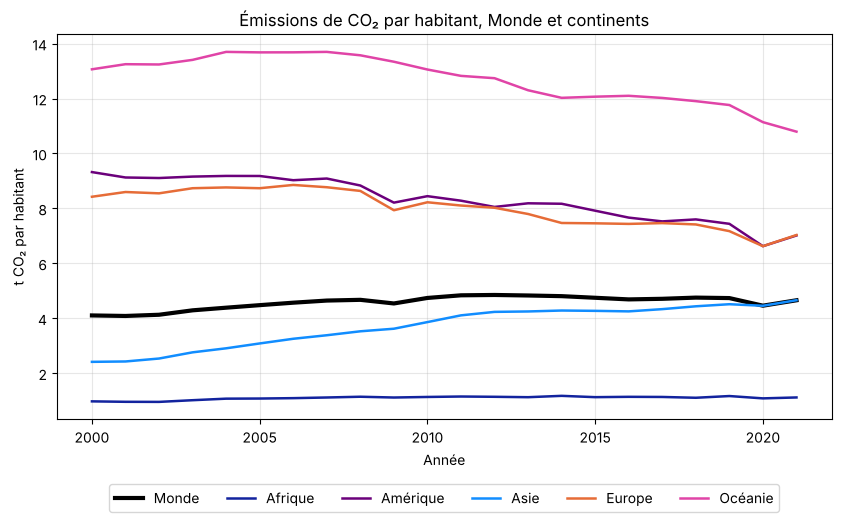

,Monde,Afrique,Amérique,Asie,Europe,Océanie
annee,,,,,,
2000,4.10,0.98,9.32,2.41,8.42,13.06
2005,4.48,1.08,9.18,3.08,8.74,13.68
2010,4.74,1.14,8.45,3.86,8.22,13.06
2015,4.75,1.13,7.92,4.27,7.46,12.07
2019,4.74,1.17,7.44,4.51,7.17,11.76
2020,4.46,1.09,6.63,4.46,6.62,11.14
2021,4.66,1.12,7.02,4.66,7.03,10.79


annee,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
emissions_t_hab,4.13,4.29,4.39,4.48,4.57,4.65,4.67,4.54,4.74,4.84,4.85,4.83
variation_pct,1.07,3.90,2.24,2.11,2.00,1.70,0.57,-2.83,4.42,2.02,0.26,-0.39


In [8]:
monde = evolution_monde()
continents = emissions_par_continent()
emissions_annuelles = monde[["emissions_t_hab"]].rename(columns={"emissions_t_hab": "Monde"}).join(continents)

fig, ax = plt.subplots(figsize=(10, 5))
for colonne in emissions_annuelles.columns:
    ax.plot(emissions_annuelles.index, emissions_annuelles[colonne], label=colonne,
            linewidth=3 if colonne == "Monde" else 1.8,
            color="black" if colonne == "Monde" else COULEURS_CONTINENTS[colonne])
ax.set_title("Émissions de CO₂ par habitant, Monde et continents")
ax.set_xlabel("Année")
ax.set_ylabel("t CO₂ par habitant")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=6)
ax.grid(alpha=0.3)
plt.show()

display(emissions_annuelles.loc[[2000, 2005, 2010, 2015, 2019, 2020, 2021]].round(2))
display(monde.loc[2002:2013].round(2).T)

Les émissions mondiales par habitant passent de 4,1 t en 2000 à 4,85 t en 2012. Leur croissance ralentit pourtant dès le milieu des années 2000 : elle passe de 3,9 % en 2003 à 0,6 % en 2008. La crise financière provoque une baisse de 2,8 % en 2009, suivie d'un rebond en 2010 et 2011. Le maximum est atteint en 2012, puis les émissions reculent légèrement et se stabilisent autour de 4,7 t jusqu'en 2019. L'année 2020 marque une baisse dans tous les continents, liée à la crise sanitaire, suivie d'une reprise en 2021.

Ce plateau mondial cache des évolutions opposées. L'Amérique et l'Europe baissent nettement, de 9,3 t à 7,4 t et de 8,4 t à 7,2 t entre 2000 et 2019. L'Asie suit le chemin inverse : elle passe de 2,4 t à 4,5 t et rejoint presque la moyenne mondiale. L'Afrique reste très en dessous, entre 1,0 t et 1,2 t par habitant sur toute la période, soit quatre fois moins que la moyenne mondiale.

L'Océanie a les émissions les plus élevées, mais elle ne compte que trois pays de plus d'un million d'habitants, dont l'Australie qui pèse presque tout le continent. Sa courbe doit être lue comme celle de l'Australie.

### 2.2 Écart entre les pays

Une moyenne ne dit rien de l'écart entre les pays. Pour chaque année, on calcule donc plusieurs repères : le 10e centile (les pays les plus sobres), le premier quartile, la médiane, le troisième quartile et le 90e centile (les pays les plus émetteurs). Le rapport entre le 90e et le 10e centile mesure l'écart entre les deux extrémités. S'il diminue, les pays se rapprochent.

On utilise une échelle logarithmique, car les émissions vont de moins de 0,1 t à plus de 30 t par habitant.

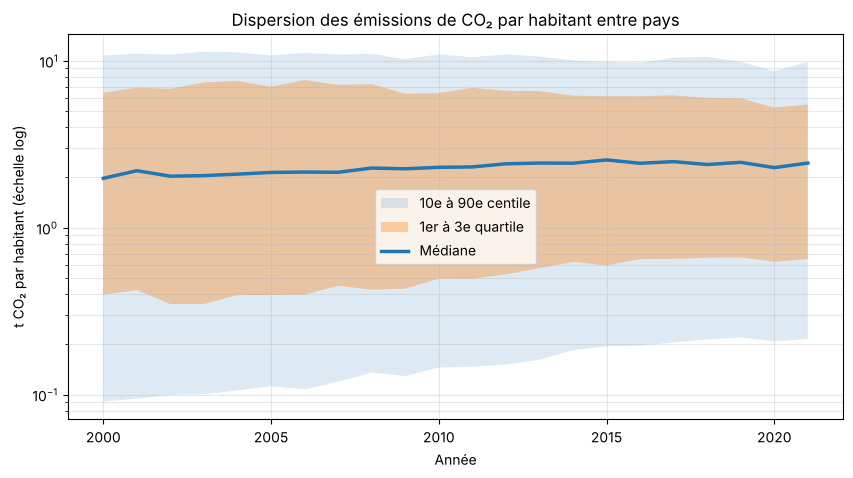

,nb_pays,p10,q1,mediane,q3,p90,rapport_p90_p10
annee,,,,,,,
2000,156,0.09,0.40,1.98,6.43,10.76,118.59
2005,157,0.11,0.40,2.14,6.99,10.77,95.86
2010,157,0.15,0.50,2.30,6.41,10.94,75.33
2015,157,0.19,0.59,2.55,6.15,9.89,50.79
2019,157,0.22,0.67,2.47,5.96,9.87,44.82
2021,157,0.22,0.65,2.44,5.47,9.89,45.76


In [9]:
dispersion = dispersion_emissions()

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(dispersion.index, dispersion["p10"], dispersion["p90"], alpha=0.15, label="10e à 90e centile")
ax.fill_between(dispersion.index, dispersion["q1"], dispersion["q3"], alpha=0.35, label="1er à 3e quartile")
ax.plot(dispersion.index, dispersion["mediane"], linewidth=2.5, label="Médiane")
ax.set_yscale("log")
ax.set_title("Dispersion des émissions de CO₂ par habitant entre pays")
ax.set_xlabel("Année")
ax.set_ylabel("t CO₂ par habitant (échelle log)")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()

display(dispersion.loc[[2000, 2005, 2010, 2015, 2019, 2021]].round(2))

L'écart entre pays reste immense, mais il se réduit nettement. En 2000, les pays du 90e centile émettaient environ 119 fois plus par habitant que ceux du 10e centile. En 2019, ce rapport tombe à 45.

Ce rapprochement vient des deux côtés. Le bas de la distribution monte : le 10e centile passe de 0,09 t à 0,22 t. Le haut baisse à partir de 2010 : le 90e centile recule de 10,9 t à 9,9 t, et le troisième quartile de 7,0 t en 2005 à 6,0 t en 2019. Les pays sobres émettent donc davantage, et les gros émetteurs réduisent.

### 2.3 Évolution pays par pays

Pour savoir quels pays montent et lesquels baissent, on calcule la variation des émissions de chaque pays entre 2010 et 2019. On s'arrête en 2019 pour ne pas mélanger la tendance de fond avec le choc de 2020.

On classe les pays selon la variation en tonnes plutôt qu'en pourcentage. Un pays qui passe de 0,3 t à 1 t affiche +200 %, alors que le changement reste faible pour chaque habitant. La variation en tonnes donne le poids réel du changement.

In [10]:
variation = variation_emissions(2010, 2019)
colonnes = ["nom_pays", "continent", "emissions_debut", "emissions_fin", "variation_t", "variation_pct"]

resume = variation.groupby("continent").agg(nb_pays=("code_iso", "count"),
                                            nb_en_baisse=("variation_t", lambda v: (v < 0).sum()))
resume["part_en_baisse_pct"] = resume["nb_en_baisse"] / resume["nb_pays"] * 100
print(f"{len(variation)} pays, dont {(variation['variation_t'] < 0).sum()} en baisse entre 2010 et 2019")
display(resume.round(0))

print("Plus fortes baisses (tonnes par habitant)")
display(variation.head(5)[colonnes].round(2))
print("Plus fortes hausses (tonnes par habitant)")
display(variation.tail(5).iloc[::-1][colonnes].round(2))

157 pays, dont 65 en baisse entre 2010 et 2019


,nb_pays,nb_en_baisse,part_en_baisse_pct
continent,,,
Afrique,50,11,22.0
Amérique,24,11,46.0
Asie,45,13,29.0
Europe,35,28,80.0
Océanie,3,2,67.0


Plus fortes baisses (tonnes par habitant)


,nom_pays,continent,emissions_debut,emissions_fin,variation_t,variation_pct
0,Kuwait,Asie,30.33,23.50,-6.83,-22.52
1,Trinidad and Tobago,Amérique,33.30,26.82,-6.47,-19.44
2,Qatar,Asie,41.97,36.03,-5.94,-14.15
3,Singapore,Asie,10.66,5.10,-5.56,-52.18
4,Estonia,Europe,14.24,9.27,-4.97,-34.92


Plus fortes hausses (tonnes par habitant)


,nom_pays,continent,emissions_debut,emissions_fin,variation_t,variation_pct
156,Mongolia,Asie,5.10,14.62,9.52,186.86
155,Lao People's Democratic Republic,Asie,0.48,2.72,2.24,471.86
154,Viet Nam,Asie,1.59,3.56,1.97,124.57
153,Bahrain,Asie,23.96,25.31,1.35,5.64
152,United Arab Emirates,Asie,21.30,22.63,1.34,6.29


Entre 2010 et 2019, 65 pays sur 157 réduisent leurs émissions par habitant. La baisse est très majoritaire en Europe, où elle concerne 28 pays sur 35, et minoritaire en Afrique et en Asie, avec respectivement 11 pays sur 50 et 13 sur 45.

Les plus fortes baisses concernent des pays qui partaient de niveaux très élevés : le Koweït, Trinité-et-Tobago et le Qatar perdent chacun entre 6 et 7 t par habitant, mais restent au-dessus de 20 t. Les plus fortes hausses viennent de pays en forte croissance économique, comme la Mongolie, qui gagne 9,5 t par habitant, ou le Laos et le Viet Nam.

Pour illustrer ces tendances, on suit quelques pays : les trois plus gros émetteurs en volume (Chine, États-Unis, Inde), deux grands pays européens (Allemagne, France), et un pays par autre continent (Brésil, Afrique du Sud, Sénégal).

,nom_pays,continent,emissions_debut,emissions_fin,variation_t,variation_pct
11,United States of America,Amérique,18.16,15.65,-2.51,-13.80
17,Germany,Europe,10.13,8.40,-1.73,-17.08
28,France,Europe,5.97,4.85,-1.12,-18.69
31,South Africa,Afrique,8.94,8.04,-0.90,-10.06
65,Brazil,Amérique,2.21,2.21,0.00,0.06
115,Senegal,Afrique,0.55,0.80,0.25,45.63
133,India,Asie,1.35,1.90,0.55,40.52
148,China,Asie,6.31,7.43,1.12,17.83


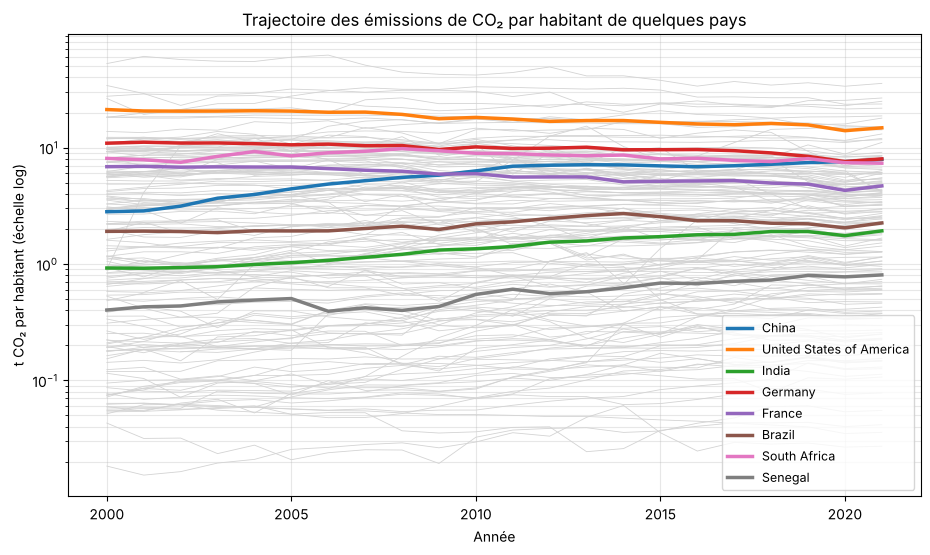

In [11]:
PAYS_SUIVIS = ["CHN", "USA", "IND", "DEU", "FRA", "BRA", "ZAF", "SEN"]
display(variation[variation["code_iso"].isin(PAYS_SUIVIS)][colonnes].round(2))
trajectoires_emissions(PAYS_SUIVIS, "Trajectoire des émissions de CO₂ par habitant de quelques pays")

Les pays suivis confirment l'opposition entre pays développés et pays en développement. Les États-Unis, l'Allemagne et la France baissent de 14 à 19 % entre 2010 et 2019. La Chine, l'Inde et le Sénégal augmentent de 18 à 46 %. Le Brésil reste stable. C'est le détail du rapprochement observé en 2.2 : les pays riches réduisent leurs émissions, les pays en développement rattrapent.

## 3. Question b : émissions de CO₂ et éducation

On cherche à savoir s'il existe un lien entre les émissions de CO₂ par habitant et l'éducation. Les données ne contiennent pas de mesure du niveau d'éducation atteint, comme le taux de scolarisation ou le diplôme. On utilise donc l'effort public d'éducation, mesuré par les dépenses consacrées à l'enseignement primaire en pourcentage du PIB.

#### Ce que mesure une corrélation

Une corrélation indique si deux variables évoluent ensemble entre les pays : quand l'une est élevée, l'autre l'est-elle aussi (corrélation positive), ou au contraire faible (corrélation négative) ? Elle varie entre −1 et 1, et vaut 0 en l'absence de lien.

On utilise la corrélation de Spearman plutôt que celle de Pearson. Pearson ne mesure qu'un lien linéaire et se laisse tirer par les valeurs extrêmes. Or les émissions vont de 0,03 t à plus de 30 t par habitant. Spearman compare les rangs des pays plutôt que leurs valeurs : elle détecte tout lien monotone, linéaire ou non, et n'est pas déformée par quelques pays très émetteurs.

#### La démarche

On compare les pays entre eux, une année à la fois, pour que chaque pays n'apparaisse qu'une fois et que les observations soient indépendantes. On vérifie d'abord sur quelles années les dépenses d'éducation sont disponibles, puis on teste le lien sur l'année la mieux couverte, on cherche un éventuel lien non monotone, on vérifie que le résultat tient sur toutes les années, et enfin qu'il n'est pas masqué par le niveau de richesse des pays.

### 3.1 Les dépenses d'éducation : couverture et choix de l'année

Seuls les pays qui ont à la fois une valeur d'éducation et une valeur d'émissions peuvent entrer dans le test. On compte ces pays pour chaque année, et on regarde leur répartition par continent : si un continent disparaît certaines années, l'échantillon change de nature, et le résultat du test peut changer avec lui.

In [12]:
couverture = couverture_education()
display(couverture.round(2))
display(couverture_par_continent())

,nb_pays_deux_variables,q1,mediane,q3
annee,,,,
2010,91,0.97,1.39,1.83
2011,93,0.94,1.40,1.81
2012,90,0.97,1.42,1.81
2013,94,1.03,1.46,1.89
2014,87,1.05,1.45,1.71
2015,86,1.06,1.45,1.79
2016,86,1.09,1.42,1.75
2017,82,0.99,1.34,1.65
2018,80,0.98,1.37,1.56


annee,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
continent,,,,,,,,,,,,
Afrique,32,28,29,30,26,22,19,14,12,11,11,12
Amérique,17,15,15,15,15,17,18,16,17,17,13,10
Asie,18,24,22,22,20,20,22,21,20,23,19,13
Europe,23,25,23,25,24,25,25,29,29,28,2,1
Océanie,1,1,1,2,2,2,2,2,2,2,0,0


Les dépenses d'éducation ne sont disponibles qu'à partir de 2010. Entre 2010 et 2019, entre 80 et 94 pays ont les deux variables renseignées. La couverture s'effondre ensuite, avec 45 pays en 2020 et 36 en 2021. L'indicateur évolue peu : la médiane reste entre 1,26 % et 1,46 % du PIB.

La composition de l'échantillon change beaucoup. L'Afrique passe de 32 pays renseignés en 2010 à 11 en 2019, alors que l'Europe passe de 23 à 28, puis disparaît presque en 2020 et 2021. Or l'Afrique a les émissions les plus faibles et l'Europe parmi les plus élevées. Un résultat différent selon l'année pourrait donc venir du changement de pays, et non d'une évolution du lien.

La carte ci-dessous montre cette couverture pays par pays. Une case colorée signifie que le pays a les deux variables cette année-là.

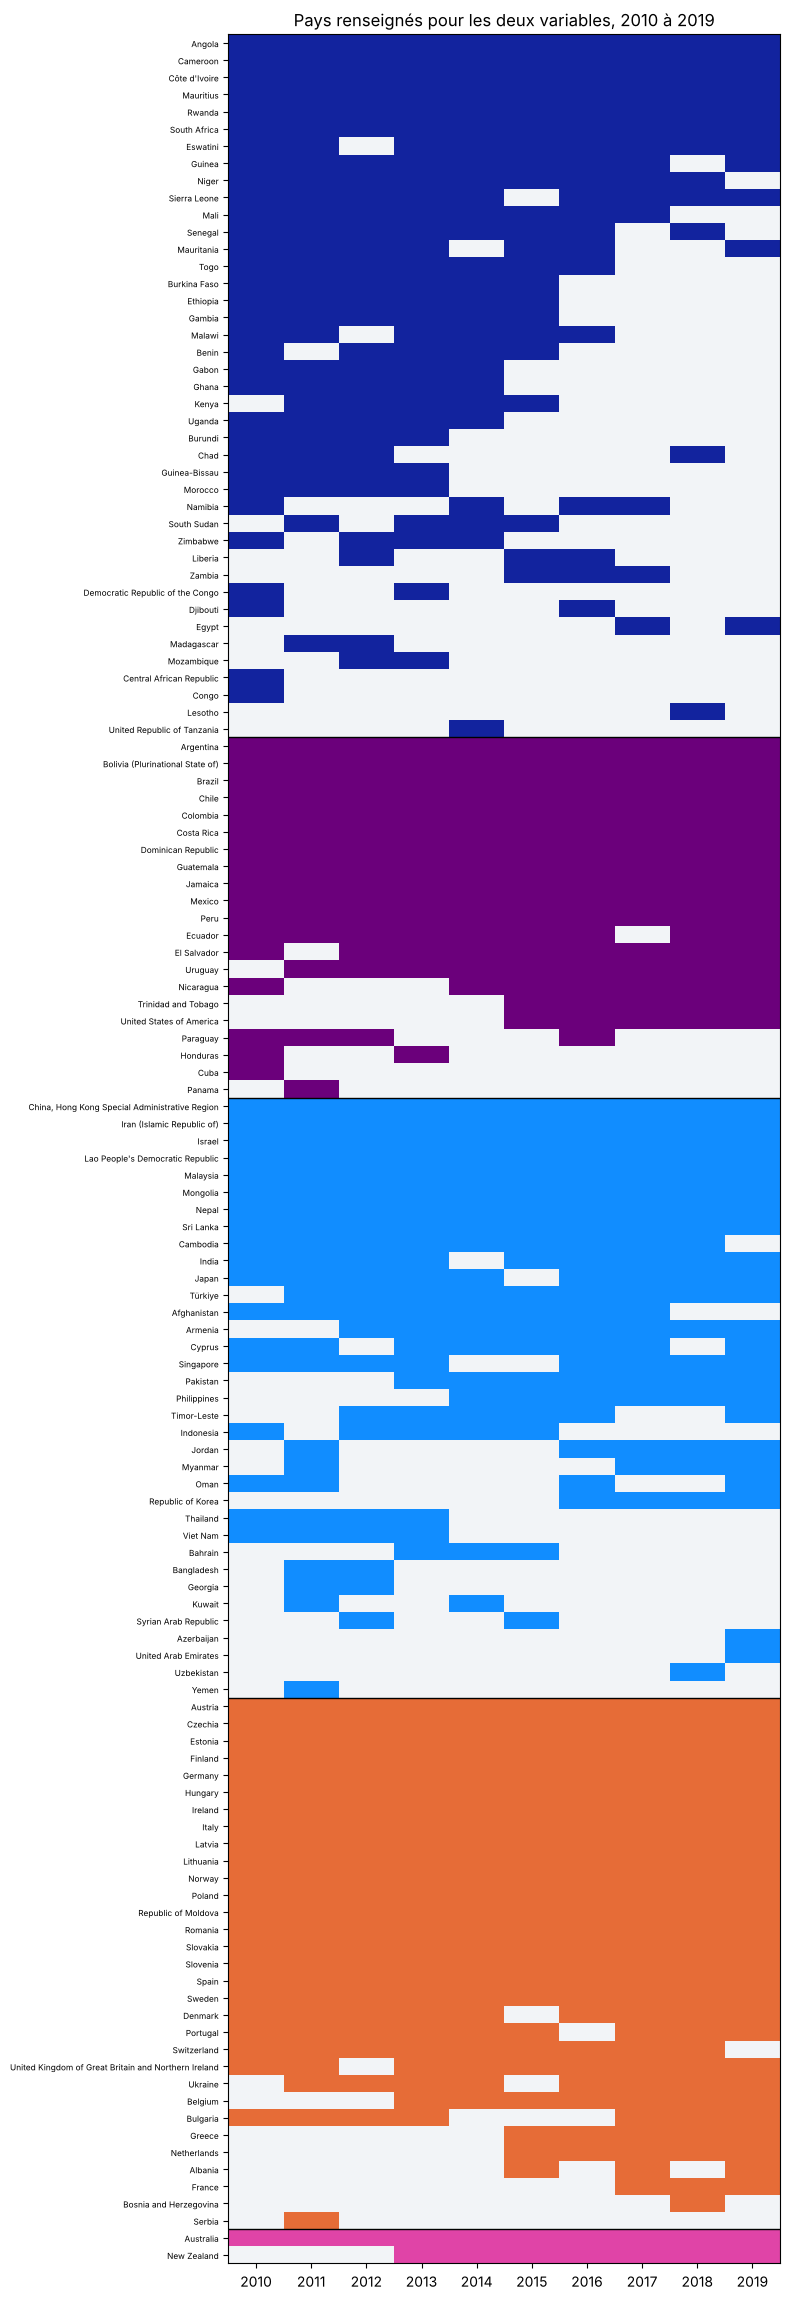

130 pays apparaissent au moins une année, dont 44 sur les 10 années


nb_annees,1,2,3,4,5,6,7,8,9,10
nb_pays,12,10,5,13,11,6,7,7,15,44


In [13]:
repartition_annees = heatmap_couverture(2010, 2019)
print(f"{repartition_annees.sum()} pays apparaissent au moins une année, "
      f"dont {repartition_annees.get(10, 0)} sur les 10 années")
display(repartition_annees.to_frame().T)

Sur la période, 130 pays apparaissent au moins une année, mais seulement 44 sont présents les dix années. Les absences ne sont pas réparties au hasard : beaucoup de pays africains sont renseignés en début de période puis disparaissent, alors que les pays européens sont présents presque chaque année.

On retient donc 2013 pour le test principal : c'est l'année la mieux couverte, avec 94 pays, et l'Afrique y est encore bien représentée avec 30 pays. Les années 2020 et 2021 sont écartées, car trop peu de pays sont renseignés et la crise sanitaire perturbe les émissions. Pour vérifier que le résultat ne dépend pas de la composition de l'échantillon, on refera le test sur les 44 pays présents toutes les années (partie 3.4).

### 3.2 Test du lien en 2013

On teste l'existence d'un lien monotone entre les émissions de CO₂ par habitant ($x$) et les dépenses publiques pour le primaire en pourcentage du PIB ($y$).

$$H_0 : \rho_s = 0 \quad \text{(absence de lien monotone)}$$
$$H_1 : \rho_s \neq 0 \quad \text{(lien monotone, positif ou négatif)}$$

Le test est bilatéral, au seuil $\alpha = 5\,\%$. Sans ex æquo, la corrélation de Spearman s'écrit :

$$\rho_s = 1 - \frac{6 \sum_{i=1}^{n} d_i^2}{n(n^2 - 1)}$$

où $d_i$ est l'écart entre le rang du pays $i$ pour les émissions et son rang pour l'éducation, et $n$ le nombre de pays. Sous $H_0$, la statistique suivante suit une loi de Student à $n - 2$ degrés de liberté :

$$t = \rho_s \sqrt{\frac{n-2}{1-\rho_s^2}} \;\sim\; \mathcal{T}(n-2)$$

On complète le test par un intervalle de confiance à 95 %, obtenu par bootstrap : on tire 5 000 fois un échantillon de pays avec remise et on recalcule la corrélation. Il indique quelle taille de lien reste compatible avec les données, ce que la p-value seule ne dit pas.

Ne pas rejeter $H_0$ ne démontre pas l'absence de lien. Cela signifie seulement que les données ne permettent pas de mettre en évidence un lien monotone.

94 pays en 2013


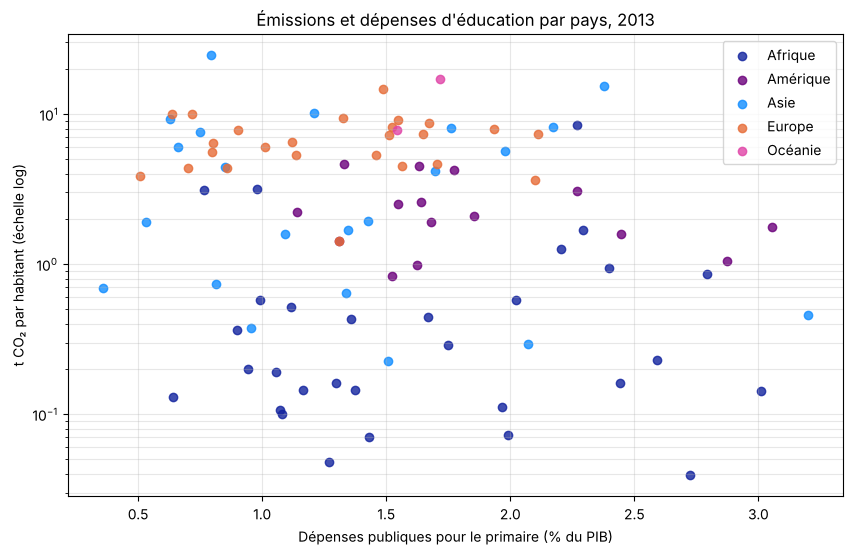

,résultat
nb_pays,94.000
rho,-0.121
p_value,0.244
ic_bas,-0.319
ic_haut,0.095


In [14]:
ANNEE_REFERENCE = 2013
donnees_2013 = donnees_annee(ANNEE_REFERENCE)
print(f"{len(donnees_2013)} pays en {ANNEE_REFERENCE}")

nuage_emissions_education(donnees_2013, f"Émissions et dépenses d'éducation par pays, {ANNEE_REFERENCE}")

resultat_2013 = tester_spearman(donnees_2013["emissions_t_hab"], donnees_2013["depenses_education_pct_pib"])
display(pd.Series(resultat_2013).round(3).to_frame("résultat"))

En 2013, la corrélation de Spearman vaut −0,12, avec une p-value de 0,24. On ne peut donc pas rejeter l'hypothèse d'absence de lien monotone.

Le nuage de points ne montre pas de tendance. Pour un même niveau de dépense d'éducation, les émissions varient de quelques dixièmes de tonne à plus de 10 t par habitant. Les pays se rangent surtout par continent sur l'axe vertical, l'Afrique en bas et l'Europe en haut, quel que soit leur effort d'éducation.

L'intervalle de confiance va de −0,32 à 0,10. Si un lien existe, il est donc faible et plutôt négatif. Un lien modéré ou fort est exclu par les données.

### 3.3 Recherche d'un lien non monotone

La corrélation de Spearman ne détecte pas un lien qui change de sens, par exemple en forme de cloche : des émissions faibles pour les pays qui dépensent peu et pour ceux qui dépensent beaucoup, et élevées entre les deux. On vérifie donc l'indépendance des deux variables avec le test du Khi², qui ne suppose aucune forme de relation.

On découpe chaque variable en quartiles et on compare les effectifs observés $O_{jk}$ du tableau croisé aux effectifs attendus $E_{jk}$ si les variables étaient indépendantes :

$$H_0 : \text{les deux variables sont indépendantes} \qquad H_1 : \text{elles sont dépendantes}$$

$$\chi^2 = \sum_{j=1}^{4} \sum_{k=1}^{4} \frac{(O_{jk} - E_{jk})^2}{E_{jk}} \;\sim\; \chi^2(9)$$

Le test est valable si tous les effectifs attendus sont au moins égaux à 5.

In [15]:
tableau_quartiles, resultat_independance = tester_independance(
    donnees_2013["emissions_t_hab"], donnees_2013["depenses_education_pct_pib"])
tableau_quartiles.index.name = "Émissions"
tableau_quartiles.columns.name = "Éducation"
display(tableau_quartiles)
display(pd.Series(resultat_independance).round(3).to_frame("résultat"))

Éducation,Q1,Q2,Q3,Q4
Émissions,,,,
Q1,4,9,3,8
Q2,4,7,4,8
Q3,9,4,7,3
Q4,7,3,9,5


,résultat
khi2,13.834
ddl,9.000
p_value,0.128
effectif_attendu_min,5.628


Le Khi² vaut 13,8 pour 9 degrés de liberté, avec une p-value de 0,13 : on ne rejette pas l'indépendance. Les effectifs attendus sont tous supérieurs à 5, le test est donc valable. Le tableau croisé ne montre pas de structure régulière : chaque quartile d'émissions contient des pays de tous les niveaux de dépense d'éducation. Il n'y a donc pas de lien non monotone que Spearman aurait manqué.

### 3.4 Le résultat tient-il sur toutes les années ?

On refait le test de Spearman pour chaque année de 2010 à 2019, de deux façons. La première utilise tous les pays disponibles chaque année. La seconde utilise seulement les 44 pays présents les dix années. Si la corrélation ne varie que dans la première version, ce sont les changements de pays qui la font bouger, et non une évolution du lien.

On réalise ici dix tests. Même sans aucun lien réel, il ne serait pas étonnant qu'une année sur dix donne une p-value proche de 0,05 par hasard. Un résultat isolé ne suffirait donc pas à conclure.

,nb_pays,rho,p_value,nb_pays_constant,rho_constant,p_value_constant
annee,,,,,,
2010,91,-0.019,0.855,44,-0.053,0.731
2011,93,-0.052,0.618,44,-0.004,0.978
2012,90,-0.129,0.226,44,-0.023,0.880
2013,94,-0.121,0.244,44,0.006,0.969
2014,87,-0.134,0.215,44,0.049,0.754
2015,86,-0.191,0.078,44,-0.086,0.578
2016,86,-0.154,0.158,44,-0.128,0.408
2017,82,-0.052,0.643,44,-0.050,0.745
2018,80,-0.067,0.553,44,0.062,0.688


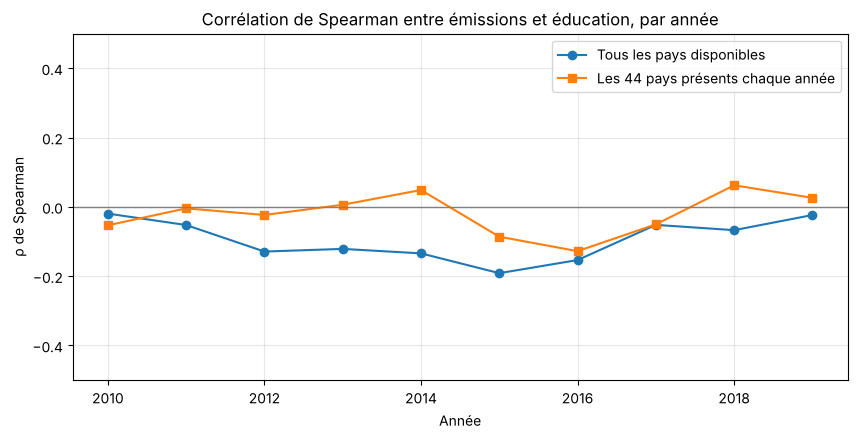

In [16]:
robustesse, pays_constants = correlation_par_annee(2010, 2019)
display(robustesse.round(3))
graphe_correlation_par_annee(robustesse, len(pays_constants))

Sur les dix années, la corrélation reste faible et négative, entre −0,19 et −0,02, et aucune année n'est significative au seuil de 5 %. La valeur la plus marquée, en 2015, donne une p-value de 0,08.

Sur les 44 pays présents chaque année, la corrélation est encore plus proche de zéro, entre −0,13 et 0,06, avec des p-values toutes supérieures à 0,4. Les petites variations observées sur l'ensemble des pays viennent donc surtout du changement de composition de l'échantillon. Le résultat de 2013 est robuste.

Cet échantillon constant ne compte que 44 pays, ce qui réduit la puissance du test. Il sert de contrôle de cohérence, pas de résultat principal.

### 3.5 Vérification à richesse égale

L'absence de lien pourrait être masquée par un troisième facteur. Le plus évident est le niveau de développement, qui influence fortement les émissions. Si, par exemple, les pays riches émettaient beaucoup et dépensaient aussi beaucoup pour l'école, alors qu'à richesse égale les pays qui dépensent plus émettaient moins, les deux effets pourraient se compenser et donner une corrélation proche de zéro.

On calcule donc la corrélation partielle de Spearman, qui mesure le lien entre émissions ($x$) et éducation ($y$) à PIB par habitant ($z$) égal :

$$\rho_{xy \cdot z} = \frac{\rho_{xy} - \rho_{xz}\,\rho_{yz}}{\sqrt{(1-\rho_{xz}^2)(1-\rho_{yz}^2)}}$$

$$H_0 : \rho_{xy \cdot z} = 0 \qquad t = \rho_{xy \cdot z} \sqrt{\frac{n-3}{1-\rho_{xy \cdot z}^2}} \;\sim\; \mathcal{T}(n-3)$$

Le numérateur retire du lien entre $x$ et $y$ la part qui passe par $z$. On perd un degré de liberté de plus qu'à la partie 3.2, pour la variable contrôlée.

In [17]:
controle_richesse = correlation_partielle_par_annee(2010, 2019)
display(controle_richesse.round(3))

,nb_pays,rho_simple,rho_partiel,p_value_partiel
annee,,,,
2010,88,0.014,-0.020,0.852
2011,90,-0.038,0.063,0.559
2012,88,-0.109,0.022,0.842
2013,93,-0.099,0.030,0.777
2014,86,-0.130,0.015,0.893
2015,86,-0.191,-0.046,0.675
2016,84,-0.140,-0.039,0.725
2017,81,-0.051,-0.049,0.663
2018,79,-0.066,-0.005,0.966


À PIB par habitant égal, la corrélation reste proche de zéro sur toutes les années, entre −0,05 et 0,06, avec des p-values supérieures à 0,5. Aucun lien n'était donc masqué par le niveau de développement.

Le nombre de pays est légèrement inférieur à celui des parties précédentes, car les pays sans population connue n'ont pas de PIB par habitant et sont retirés de ce calcul.

### 3.6 Synthèse et export pour le tableau de bord

On rassemble les résultats des tests de 2013 dans un tableau unique, puis on exporte trois fichiers dans le dossier `data/resultats` pour la page de la question b dans Power BI. Ces calculs ne sont pas faisables simplement en DAX, c'est pourquoi ils sont réalisés ici.

In [18]:
synthese_tests = pd.DataFrame([
    {"test": "Spearman", "forme_de_lien": "monotone",
     "statistique": resultat_2013["rho"], "p_value": resultat_2013["p_value"],
     "nb_pays": resultat_2013["nb_pays"]},
    {"test": "Khi² d'indépendance", "forme_de_lien": "toute forme",
     "statistique": resultat_independance["khi2"], "p_value": resultat_independance["p_value"],
     "nb_pays": resultat_2013["nb_pays"]},
    {"test": "Spearman partiel", "forme_de_lien": "monotone, à richesse égale",
     "statistique": controle_richesse.loc[2013, "rho_partiel"], "p_value": controle_richesse.loc[2013, "p_value_partiel"],
     "nb_pays": controle_richesse.loc[2013, "nb_pays"]},
])
synthese_tests["significatif_5pct"] = synthese_tests["p_value"] < 0.05
display(synthese_tests.round(3))
print(f"Intervalle de confiance à 95 % en 2013 : [{resultat_2013['ic_bas']:.2f} ; {resultat_2013['ic_haut']:.2f}]")
print(f"Années significatives entre 2010 et 2019 : {(robustesse['p_value'] < 0.05).sum()} sur {len(robustesse)}")

correlation_annuelle = robustesse.join(controle_richesse[["rho_partiel", "p_value_partiel"]]).reset_index()
nuage_2013 = donnees_2013[["code_iso", "nom_pays", "continent", "emissions_t_hab", "depenses_education_pct_pib"]]

nuage_2013.to_csv(DOSSIER_RESULTATS / "correlation_pays_2013.csv", index=False)
correlation_annuelle.to_csv(DOSSIER_RESULTATS / "correlation_par_annee.csv", index=False)
synthese_tests.to_csv(DOSSIER_RESULTATS / "tests_correlation.csv", index=False)
print(f"Fichiers exportés dans {DOSSIER_RESULTATS} : correlation_pays_2013.csv, correlation_par_annee.csv, tests_correlation.csv")

,test,forme_de_lien,statistique,p_value,nb_pays,significatif_5pct
0,Spearman,monotone,-0.121,0.244,94,False
1,Khi² d'indépendance,toute forme,13.834,0.128,94,False
2,Spearman partiel,"monotone, à richesse égale",0.030,0.777,93,False


Intervalle de confiance à 95 % en 2013 : [-0.32 ; 0.10]
Années significatives entre 2010 et 2019 : 0 sur 10
Fichiers exportés dans data/resultats : correlation_pays_2013.csv, correlation_par_annee.csv, tests_correlation.csv


**Réponse à la question b.** Les données ne mettent en évidence aucun lien entre les émissions de CO₂ par habitant et les dépenses publiques pour l'enseignement primaire. En 2013, la corrélation de Spearman vaut −0,12 et n'est pas significative. Le test du Khi², qui ne suppose aucune forme de relation, ne détecte pas non plus de dépendance. Le résultat se répète chaque année de 2010 à 2019, y compris sur un échantillon constant de pays, et il reste le même à PIB par habitant égal.

Cette absence de lien n'est pas une preuve d'indépendance : si un lien existe, il est faible, l'intervalle de confiance excluant toute corrélation au-delà de 0,32 en valeur absolue. Pour la décision d'implantation, les deux critères doivent donc être étudiés séparément. Un pays qui consacre une part importante de son PIB à l'école primaire n'est pas pour autant un pays sobre en carbone.

**Limites.** L'indicateur mesure un effort budgétaire et non un niveau d'éducation atteint, et il ne couvre que le primaire. Il n'est disponible que pour environ 90 pays par an. Enfin, le contrôle a porté sur la richesse, mais d'autres facteurs absents des données, comme le mix énergétique, pourraient jouer un rôle.

## 4. Question c : pays à la plus faible empreinte carbone

L'empreinte carbone est mesurée ici par les émissions territoriales de CO₂ par habitant. Ce choix avantage les pays qui importent leurs produits industriels, puisque les émissions de leur fabrication sont comptées dans le pays producteur.

On identifie d'abord les pays les plus sobres, puis on vérifie que ce classement est durable, avant d'étudier l'évolution de ces pays. Comme ils sont presque tous africains, on regarde enfin les pays les plus sobres de chaque continent. L'évolution des continents a déjà été décrite dans la partie 2.1.

### 4.1 Classement

On classe les pays en 2019, dernière année avant la crise sanitaire, et en 2021, dernière année disponible. La dernière colonne indique combien de fois un habitant du pays émet moins que la moyenne mondiale.

In [19]:
classement_2019 = classement_emissions(2019)
classement_2021 = classement_emissions(2021)
print(f"Moyenne mondiale : {monde.loc[2019, 'emissions_t_hab']:.2f} t en 2019, {monde.loc[2021, 'emissions_t_hab']:.2f} t en 2021")
display(classement_2019.round(3))
display(classement_2021.round(3))

Moyenne mondiale : 4.74 t en 2019, 4.66 t en 2021


,code_iso,nom_pays,continent,emissions_t_hab,fois_moins_que_monde
rang,,,,,
1,COD,Democratic Republic of the Congo,Afrique,0.029,163.428
2,SOM,Somalia,Afrique,0.040,118.721
3,CAF,Central African Republic,Afrique,0.044,108.607
4,BDI,Burundi,Afrique,0.060,78.342
5,MWI,Malawi,Afrique,0.084,56.096
6,NER,Niger,Afrique,0.105,44.977
7,TCD,Chad,Afrique,0.119,39.733
8,UGA,Uganda,Afrique,0.140,33.836
9,RWA,Rwanda,Afrique,0.141,33.547


,code_iso,nom_pays,continent,emissions_t_hab,fois_moins_que_monde
rang,,,,,
1,COD,Democratic Republic of the Congo,Afrique,0.027,171.293
2,SOM,Somalia,Afrique,0.036,130.187
3,CAF,Central African Republic,Afrique,0.042,111.792
4,BDI,Burundi,Afrique,0.055,84.343
5,MWI,Malawi,Afrique,0.078,59.665
6,NER,Niger,Afrique,0.107,43.567
7,TCD,Chad,Afrique,0.113,41.235
8,UGA,Uganda,Afrique,0.126,36.936
9,RWA,Rwanda,Afrique,0.130,35.726


Les dix pays les plus sobres sont tous africains. En 2019, un habitant de la République démocratique du Congo émet 0,03 t de CO₂, environ 160 fois moins que la moyenne mondiale de 4,74 t. Même le dixième pays, la Sierra Leone, émet environ 30 fois moins que la moyenne mondiale. Le classement de 2021 est presque identique : seule la dixième place change, Madagascar remplaçant la Sierra Leone.

Ces pays comptent parmi les moins développés du monde. Leur faible empreinte reflète un accès limité à l'énergie et une industrie peu développée, plutôt qu'une politique de réduction des émissions.

### 4.2 Stabilité du classement

Un classement sur une seule année peut dépendre d'une valeur exceptionnelle. On compte donc, pour chaque pays, le nombre d'années où il figure parmi les dix plus sobres, sur les 22 années de 2000 à 2021.

In [20]:
stabilite = stabilite_classement()
display(stabilite)

,nom_pays,continent,nb_annees_parmi_les_plus_sobres
0,Burundi,Afrique,22
1,Central African Republic,Afrique,22
2,Democratic Republic of the Congo,Afrique,22
3,Niger,Afrique,22
4,Rwanda,Afrique,22
5,Somalia,Afrique,22
6,Malawi,Afrique,19
7,Ethiopia,Afrique,17
8,Uganda,Afrique,17
9,Chad,Afrique,14


Six pays figurent parmi les dix plus sobres les 22 années : la République démocratique du Congo, le Burundi, la Somalie, le Niger, la République centrafricaine et le Rwanda. Le Malawi, l'Éthiopie et l'Ouganda y sont presque toujours. Le classement est donc très stable : les pays les plus sobres le sont durablement, et non à cause d'une année particulière.

### 4.3 Évolution des pays les plus sobres

On compare les émissions des dix pays les plus sobres de 2019 avec leur niveau de 2000, et on trace leur trajectoire sur le fond de tous les autres pays.

,nom_pays,emissions_debut,emissions_fin,variation_t,variation_pct
58,Democratic Republic of the Congo,0.018,0.029,0.011,57.826
53,Somalia,0.055,0.040,-0.015,-27.513
51,Central African Republic,0.062,0.044,-0.019,-30.093
59,Burundi,0.043,0.060,0.017,40.642
57,Malawi,0.077,0.084,0.007,9.543
65,Niger,0.060,0.105,0.046,76.373
68,Chad,0.059,0.119,0.060,102.020
74,Uganda,0.057,0.140,0.083,147.070
70,Rwanda,0.064,0.141,0.078,122.264
69,Sierra Leone,0.072,0.148,0.076,105.716


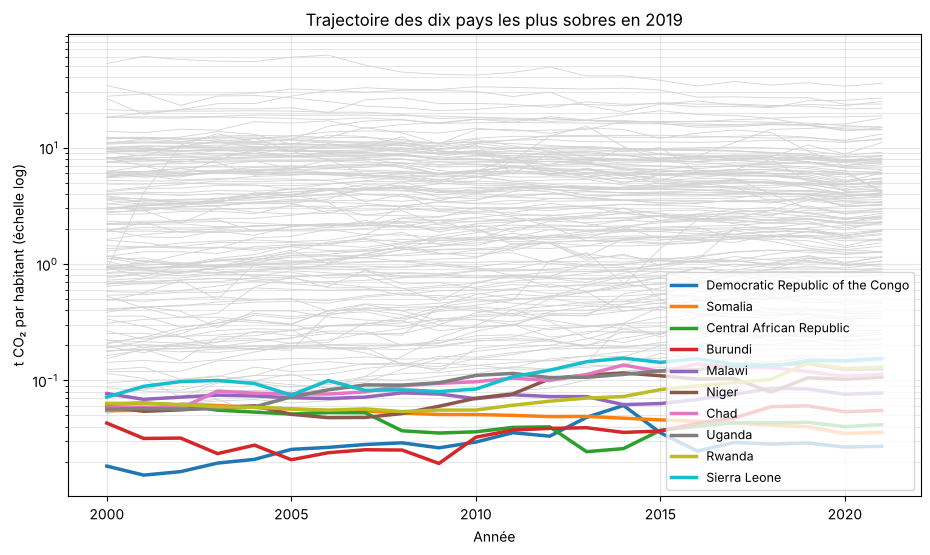

In [21]:
evolution_sobres = variation_emissions(2000, 2019)
evolution_sobres = evolution_sobres[evolution_sobres["code_iso"].isin(classement_2019["code_iso"])]
display(evolution_sobres.sort_values("emissions_fin")[
    ["nom_pays", "emissions_debut", "emissions_fin", "variation_t", "variation_pct"]].round(3))
trajectoires_emissions(classement_2019["code_iso"].tolist(), "Trajectoire des dix pays les plus sobres en 2019")

Huit des dix pays augmentent leurs émissions entre 2000 et 2019, et quatre les font plus que doubler, comme l'Ouganda, le Rwanda ou le Tchad. Ces hausses restent minimes en valeur absolue : l'Ouganda passe de 0,06 t à 0,14 t par habitant, toujours plus de trente fois sous la moyenne mondiale. Le graphique montre que ces pays restent tous dans le bas de la distribution sur l'ensemble de la période.

Seules la Somalie et la République centrafricaine baissent. Ces deux pays ont connu des conflits durables, et leur baisse reflète un recul de l'activité économique plutôt qu'une transition énergétique.

### 4.4 Les pays les plus sobres de chaque continent

Comparer tous les pays ensemble place l'Afrique en tête et masque les autres régions. Pour une entreprise qui hésite entre plusieurs zones, il est utile de connaître aussi les pays les plus sobres de chaque continent.

In [22]:
display(pays_sobres_par_continent(2019).round(2))

,continent,nom_pays,emissions_t_hab
0,Afrique,Democratic Republic of the Congo,0.03
1,Afrique,Somalia,0.04
2,Afrique,Central African Republic,0.04
3,Amérique,Haiti,0.27
4,Amérique,Nicaragua,0.78
5,Amérique,Honduras,1.13
6,Asie,Afghanistan,0.29
7,Asie,Yemen,0.40
8,Asie,Nepal,0.47
9,Europe,Albania,1.72


Hors d'Afrique, les pays les plus sobres sont Haïti, le Nicaragua et le Honduras en Amérique, l'Afghanistan, le Yémen et le Népal en Asie, l'Albanie et la Moldavie en Europe. Comme en Afrique, il s'agit surtout de pays à faible développement économique. En Europe, même les pays les plus sobres émettent environ 1,7 t par habitant, plus que la moyenne africaine.

**Réponse à la question c.** Les pays à la plus faible empreinte carbone par habitant sont tous africains, avec la République démocratique du Congo, la Somalie et la République centrafricaine en tête, à moins de 0,05 t par habitant en 2019, soit plus de cent fois moins que la moyenne mondiale. Ce classement est très stable depuis 2000. Les émissions de la plupart de ces pays augmentent, parfois de plus du double, mais restent à des niveaux très bas. Au niveau des continents, l'Afrique reste stable autour de 1,1 t par habitant, l'Europe et l'Amérique baissent, et l'Asie augmente fortement.

**Limites.** Les émissions sont territoriales et ne comptent pas les biens importés. L'Océanie ne compte que trois pays, sa moyenne se résume presque à celle de l'Australie.

## 5. Synthèse : croiser croissance et empreinte carbone

Les pays les plus sobres sont aussi les moins développés, ce qui en fait rarement des cibles d'implantation. Pour préparer la recommandation, on croise donc les deux critères utiles à l'entreprise : une forte croissance économique (question a) et une empreinte carbone modérée (question c). Pour les vingt pays à plus forte croissance du PIB entre 2010 et 2021, on affiche leurs émissions par habitant en 2019, en pourcentage de la moyenne mondiale, et leur évolution depuis 2010. Les émissions sont prises en 2019 et non en 2021 pour ne pas comparer des pays sur une année perturbée par la crise sanitaire. Les deux périodes se recouvrent presque entièrement.

In [23]:
croisement = croiser_croissance_empreinte(croissance, 2019)
display(croisement.round(1))

,nom_pays,continent,croissance_annuelle_pct,emissions_2019_t_hab,part_de_la_moyenne_mondiale_pct,variation_emissions_2010_2019_pct
0,Timor-Leste,Asie,13.7,0.5,11.3,28.2
1,Ethiopia,Afrique,12.7,0.2,3.4,125.8
2,Bangladesh,Asie,12.4,0.6,11.7,52.2
3,Djibouti,Afrique,10.8,0.4,7.7,-35.0
4,China,Asie,10.2,7.4,156.9,17.8
5,Lao People's Democratic Republic,Asie,9.2,2.7,57.4,471.9
6,Democratic Republic of the Congo,Afrique,8.9,0.0,0.6,-1.9
7,Viet Nam,Asie,8.6,3.6,75.2,124.6
8,Togo,Afrique,8.5,0.3,5.6,-32.3
9,Kenya,Afrique,8.4,0.4,7.9,33.1


Sur les vingt pays à plus forte croissance, dix-sept émettent moins que la moyenne mondiale, et quatorze moins de la moitié. Une forte croissance économique ne s'accompagne donc pas forcément d'une forte empreinte carbone. Seuls trois pays dépassent la moyenne mondiale : la Chine et l'Irlande, à environ 1,6 fois la moyenne, et la Mongolie, à plus de 3 fois. Le cas de l'Irlande est à lire avec prudence : son PIB est gonflé par les bénéfices des multinationales qui y sont domiciliées, et sa croissance mesure mal l'activité réelle du pays.

Le tableau fait apparaître trois profils. Le premier regroupe les pays à forte croissance dont l'empreinte reste très faible, sous 25 % de la moyenne mondiale, même quand elle augmente : l'Éthiopie, le Kenya, le Ghana, la Tanzanie, le Bangladesh ou le Guatemala. Le deuxième rassemble les pays dont l'empreinte reste sous la moyenne mais augmente très vite, comme le Viet Nam, le Cambodge et le Laos, dont les émissions ont été multipliées par 2 à 5 depuis 2010. Le troisième correspond aux pays dont la croissance s'accompagne déjà d'émissions élevées, comme la Chine et la Mongolie.

Pour une entreprise qui cherche à la fois un marché dynamique et une empreinte carbone maîtrisée, le premier profil est le plus intéressant, avec en particulier l'Afrique de l'Est et l'Asie du Sud. Ces données ne disent cependant rien de critères essentiels à une implantation logistique, comme les infrastructures, la stabilité politique ou la taille du marché. Elles servent à présélectionner des zones, que d'autres analyses devront confirmer. Cette présélection est détaillée dans la page Recommandation du tableau de bord.